# 04. Treino do baseline

Agora treinamos o modelo do `03_modelo` com os dados preparados no `02_preprocessamento`.
Só usamos o **treino oficial** do WFLW. O teste nem é aberto aqui, para que nenhuma decisão dependa dele.

1. A configuração, com todos os hiperparâmetros num lugar só
2. O `Dataset`, que aplica o augmentation em cima do cache
3. O modelo, a perda, o otimizador e a agenda da taxa de aprendizagem
4. O laço de treino, com validação ao fim de cada época
5. As curvas e o resultado

Os arquivos ficam em `runs/nb_001_baseline/`: o `best.pt` (a melhor época na validação), o
`last.pt` e o `log.csv`. O `best.pt` tem o mesmo formato que o `predict.py` espera.

In [1]:
import csv
import math
import os
import random
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset

plt.rcParams["figure.dpi"] = 90

# raiz do projeto (o notebook roda de dentro de notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"                      # WFLW (espelho público no Kaggle, ver o README)
ANN, IMG = DATA / "WFLW_annotations", DATA / "WFLW_images"
PROCESSED = DATA / "processed"            # saídas do notebook 02

## 1. Configuração

In [2]:
CONFIG = {
    "name": "nb_001_baseline",
    "seed": 42,
    "data": {"input_size": 256, "margin": 1.25, "val_fraction": 0.1},
    "augment": {"flip_prob": 0.5, "rotation": 15, "scale": [0.85, 1.2], "translation": 0.06, "color": 0.3},
    "model": {"backbone": "resnet18", "pretrained": True, "head_channels": 256, "num_deconv": 3},
    "loss": {"kind": "l1", "eye_weight": 1.0},
    "train": {"epochs": 40, "batch_size": 32, "lr": 1e-3, "backbone_lr": 2e-4,
              "weight_decay": 1e-4, "warmup_epochs": 1},
}
# execução rápida para teste: NB_EPOCHS=1 NB_LIMIT=256
CONFIG["train"]["epochs"] = int(os.environ.get("NB_EPOCHS", CONFIG["train"]["epochs"]))
LIMIT = int(os.environ["NB_LIMIT"]) if os.environ.get("NB_LIMIT") else None
OUT = ROOT / "runs" / os.environ.get("NB_RUN", CONFIG["name"])
OUT.mkdir(parents=True, exist_ok=True)

SEED = CONFIG["seed"]
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", DEVICE, "| épocas:", CONFIG["train"]["epochs"], "| saída:", OUT.relative_to(ROOT))

device: mps | épocas: 40 | saída: runs/nb_001_baseline


## 2. O Dataset com augmentation

O `Dataset` lê os recortes de 384 pixels do cache. Para cada face ele monta **uma só** matriz
afim, que junta a escala, a rotação em torno do centro e o deslocamento, e leva o recorte do
cache para a entrada de 256. Essa matriz é aplicada na imagem e nos pontos. Depois vêm o
espelhamento (com o `Mirror98`) e o ajuste de brilho e contraste. Na validação não há
augmentation: a matriz só pega o recorte do centro.

A semente de cada face depende da semente geral, da época e do índice da face, então o treino
sempre sai igual se rodarmos de novo.

In [3]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], np.float32)


def to_tensor(image_rgb):
    # (H, W, 3) uint8 RGB -> (3, H, W) float normalizado como na ImageNet
    x = (image_rgb.astype(np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
    return torch.from_numpy(x.transpose(2, 0, 1).copy())


CACHE_SIZE, CACHE_MARGIN = 384, 1.875
MIRROR = np.array((ANN / "Mirror98.txt").read_text().strip().split(","), dtype=int)


class FaceLandmarks(Dataset):
    def __init__(self, split, indices, augment=None, input_size=256, margin=1.25, seed=0):
        self.crops = np.load(PROCESSED / f"{split}_crops.npy", mmap_mode="r")
        self.landmarks = np.load(PROCESSED / f"{split}_meta.npz")["landmarks"]
        self.indices, self.augment, self.size, self.seed = np.asarray(indices), augment or {}, input_size, seed
        # pixels da entrada por pixel do cache quando a escala sorteada é 1
        self.base_scale = input_size * CACHE_MARGIN / (margin * CACHE_SIZE)
        self.epoch = 0

    def __len__(self):
        return len(self.indices)

    def matrix(self, rng):
        a = self.augment
        angle, scale, shift = 0.0, 1.0, np.zeros(2)
        if rng is not None:
            angle = rng.uniform(-a["rotation"], a["rotation"])
            scale = rng.uniform(*a["scale"])
            shift = rng.uniform(-a["translation"], a["translation"], 2)
        c = CACHE_SIZE / 2
        m = cv2.getRotationMatrix2D((c, c), angle, self.base_scale / scale)
        m[:, 2] += self.size / 2 - c + shift * self.size
        return m

    def load(self, i, rng=None):
        k = self.indices[i]
        m = self.matrix(rng)
        image = cv2.warpAffine(np.asarray(self.crops[k]), m, (self.size, self.size),
                               flags=cv2.INTER_LINEAR, borderValue=0)
        pts = self.landmarks[k].astype(np.float64) @ m[:, :2].T + m[:, 2]
        if rng is not None:
            if rng.random() < self.augment["flip_prob"]:
                image = image[:, ::-1]
                pts[:, 0] = self.size - 1 - pts[:, 0]
                pts = pts[MIRROR]
            c = self.augment["color"]
            alpha, beta = 1 + rng.uniform(-c, c), 255 * rng.uniform(-c, c) / 2
            image = np.clip(image.astype(np.float32) * alpha + beta, 0, 255).astype(np.uint8)
        return np.ascontiguousarray(image), pts.astype(np.float32)

    def __getitem__(self, i):
        rng = np.random.default_rng([self.seed, self.epoch, i]) if self.augment else None
        image, pts = self.load(i, rng)
        return to_tensor(image), torch.from_numpy(pts)

treino: 6737 faces | validação: 763 faces


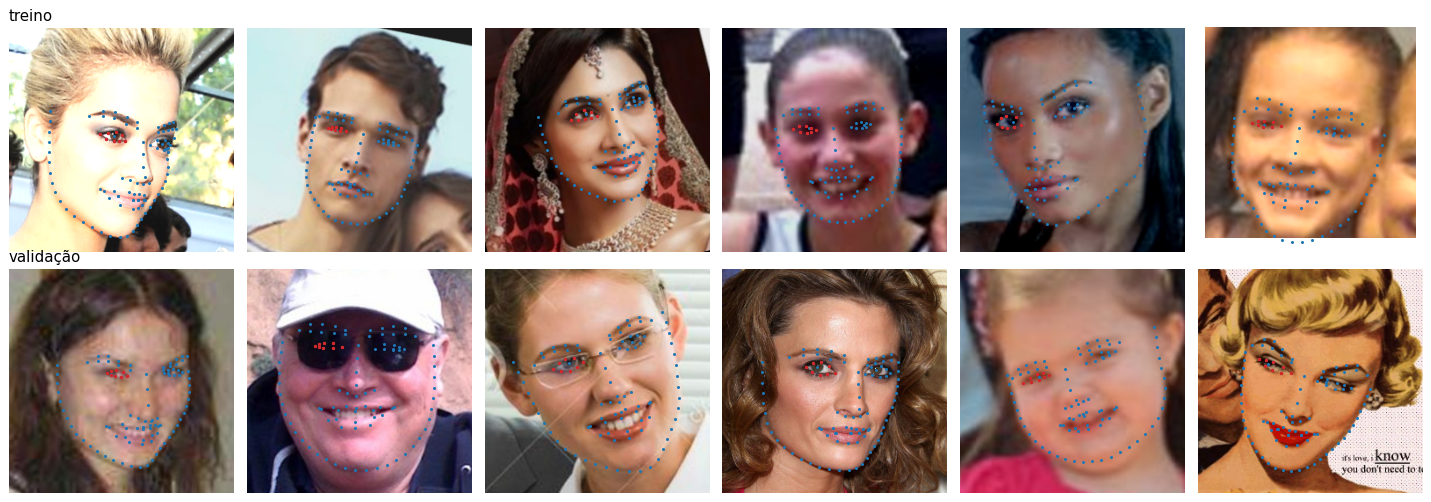

In [4]:
split = np.load(PROCESSED / "split.npz")
train_idx, val_idx = split["train_idx"], split["val_idx"]
if LIMIT:
    train_idx, val_idx = train_idx[:LIMIT], val_idx[:LIMIT]
dc = CONFIG["data"]
train_ds = FaceLandmarks("train", train_idx, CONFIG["augment"], dc["input_size"], dc["margin"], SEED)
val_ds = FaceLandmarks("train", val_idx, None, dc["input_size"], dc["margin"])
print(f"treino: {len(train_ds)} faces | validação: {len(val_ds)} faces")

# conferência visual: um lote de treino (com augmentation) e um de validação
fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
for row, ds, title in [(axes[0], train_ds, "treino"), (axes[1], val_ds, "validação")]:
    for j, ax in enumerate(row):
        rng = np.random.default_rng([SEED, 0, j]) if ds.augment else None
        im, p = ds.load(j, rng)
        ax.imshow(im); ax.scatter(p[:, 0], p[:, 1], s=2, c="tab:blue")
        ax.scatter(p[60:68, 0], p[60:68, 1], s=3, c="tab:red"); ax.axis("off")
    row[0].set_title(title, loc="left")
plt.tight_layout(); plt.show()

## 3. Modelo, perda, otimizador e agenda

- **Modelo:** o mesmo do `03_modelo`, uma ResNet-18 da ImageNet com a nossa cabeça de deconvoluções e o soft-argmax.
- **Perda:** L1 nas coordenadas dividida por 256, sem o problema dos mapas nulos.
- **Otimizador:** AdamW, que é o Adam com o weight decay aplicado direto nos pesos (uma forma
  de regularização L2). A cabeça, que começa aleatória, aprende com taxa **1e-3**, e o backbone,
  que já vem da ImageNet, com **2e-4**, só para um ajuste fino.
- **Agenda da taxa:** na primeira época a taxa sobe aos poucos de zero até o valor normal
  (warmup). Isso evita que os gradientes grandes da cabeça ainda aleatória estraguem o backbone
  logo no início. Depois a taxa vai caindo até zero seguindo uma curva de cosseno.
- **Escolha da época:** guardamos a época com o **menor NME na validação**.

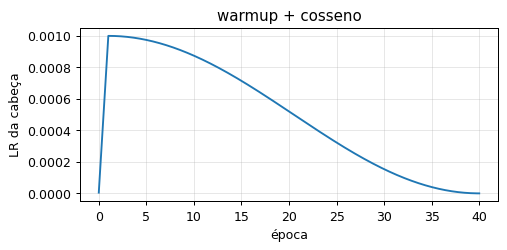

In [5]:
class LandmarkNet(nn.Module):
    """Backbone pré-treinado (sem pooling e FC) + cabeça de landmarks própria."""

    def __init__(self, num_landmarks=98, pretrained=True, head_channels=256, num_deconv=3):
        super().__init__()
        resnet = torchvision.models.resnet18(
            weights=torchvision.models.ResNet18_Weights.DEFAULT if pretrained else None)
        self.backbone = nn.Sequential(*list(resnet.children())[:-2])   # remove avgpool e fc

        layers, c_in = [], 512
        for _ in range(num_deconv):            # 8 -> 16 -> 32 -> 64
            layers += [nn.ConvTranspose2d(c_in, head_channels, 4, stride=2, padding=1, bias=False),
                       nn.BatchNorm2d(head_channels), nn.ReLU(inplace=True)]
            c_in = head_channels
        layers.append(nn.Conv2d(head_channels, num_landmarks, 1))   # 1 mapa por landmark
        self.head = nn.Sequential(*layers)
        for m in self.head.modules():
            if isinstance(m, (nn.ConvTranspose2d, nn.Conv2d)):
                nn.init.normal_(m.weight, std=0.001)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
        self.stride = 32 // (2 ** num_deconv)  # pixels da entrada por célula do mapa (4)

    def forward(self, x):
        logits = self.head(self.backbone(x))
        return soft_argmax(logits, self.stride), logits


def soft_argmax(logits, stride):
    """Coordenada esperada sob um softmax espacial, em pixels da entrada."""
    b, k, h, w = logits.shape
    prob = F.softmax(logits.reshape(b, k, h * w).float(), dim=-1).reshape(b, k, h, w)
    xs = torch.arange(w, device=logits.device, dtype=prob.dtype)
    ys = torch.arange(h, device=logits.device, dtype=prob.dtype)
    x = (prob.sum(2) * xs).sum(-1)
    y = (prob.sum(3) * ys).sum(-1)
    # a célula i cobre os pixels [stride·i, stride·i + stride − 1]; centro = stride·i + (stride − 1)/2
    return torch.stack([x, y], -1) * stride + (stride - 1) / 2


mc = CONFIG["model"]
model = LandmarkNet(pretrained=mc["pretrained"], head_channels=mc["head_channels"],
                    num_deconv=mc["num_deconv"]).to(DEVICE)

EYES = list(range(60, 76))
loss_weights = torch.ones(98)
loss_weights[EYES] = CONFIG["loss"]["eye_weight"]
loss_weights = (loss_weights / loss_weights.mean()).to(DEVICE)


def coordinate_loss(pred, target):
    return ((pred - target).abs().sum(-1) / dc["input_size"] * loss_weights).mean()


tc = CONFIG["train"]
opt = torch.optim.AdamW([
    {"params": model.backbone.parameters(), "lr": tc["backbone_lr"]},
    {"params": model.head.parameters(), "lr": tc["lr"]},
], weight_decay=tc["weight_decay"])
base_lrs = [g["lr"] for g in opt.param_groups]

g = torch.Generator().manual_seed(SEED)
train_dl = DataLoader(train_ds, tc["batch_size"], shuffle=True, drop_last=True, generator=g)
val_dl = DataLoader(val_ds, 64, shuffle=False)
steps_per_epoch = len(train_dl)
total_steps = tc["epochs"] * steps_per_epoch
warmup = tc["warmup_epochs"] * steps_per_epoch


def lr_factor(step):
    if step < warmup:
        return (step + 1) / warmup
    return 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, total_steps - warmup)))


plt.figure(figsize=(6, 2.5))
plt.plot(np.arange(total_steps) / steps_per_epoch, [tc["lr"] * lr_factor(s) for s in range(total_steps)])
plt.xlabel("época"); plt.ylabel("LR da cabeça"); plt.title("warmup + cosseno"); plt.grid(alpha=0.3)
plt.show()

## 4. O laço de treino

Em cada época o modelo passa uma vez por todo o treino, com augmentation, e depois é avaliado
na validação com as medidas que importam para o projeto: o NME, a taxa de falha (faces com
NME acima de 10 %), o NME só dos olhos e o quanto o EAR calculado com os pontos previstos
concorda com o EAR dos pontos anotados (correlação e erro médio).

In [6]:
EAR_RIGHT = (60, 61, 63, 64, 65, 67)   # p1..p6 do olho direito da pessoa
EAR_LEFT = (72, 71, 69, 68, 75, 73)    # espelho pelo Mirror98


def ear_eye(p, idx):
    p1, p2, p3, p4, p5, p6 = (p[..., i, :] for i in idx)
    n = lambda a, b: np.linalg.norm(a - b, axis=-1)
    return (n(p2, p6) + n(p3, p5)) / (2 * n(p1, p4) + 1e-9)


def ear(p):
    return (ear_eye(p, EAR_RIGHT) + ear_eye(p, EAR_LEFT)) / 2

REGIONS = {
    "contorno": range(0, 33), "sobrancelhas": range(33, 51), "nariz": range(51, 60),
    "olhos": range(60, 76), "boca": range(76, 96), "pupilas": range(96, 98),
}
EYES = list(range(60, 76))


def point_errors(pred, gt):
    # erro de cada ponto dividido pela distância entre os cantos externos dos olhos (60-72)
    d = np.linalg.norm(gt[:, 60] - gt[:, 72], axis=-1)
    return np.linalg.norm(pred - gt, axis=-1) / d[:, None]


def nme(pred, gt, points=None):
    e = point_errors(pred, gt)
    return e.mean(-1) if points is None else e[:, list(points)].mean(-1)


def summary(pred, gt):
    per_face = nme(pred, gt)
    e_gt, e_pred = ear(gt), ear(pred)
    return {"nme": per_face.mean(), "fr10": (per_face > 0.10).mean(),
            "eye_nme": nme(pred, gt, EYES).mean(),
            "ear_corr": np.corrcoef(e_gt, e_pred)[0, 1], "ear_mae": np.abs(e_gt - e_pred).mean()}


@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds, gts = [], []
    for x, y in loader:
        preds.append(model(x.to(DEVICE))[0].float().cpu().numpy())
        gts.append(y.numpy())
    return np.concatenate(preds).astype(np.float64), np.concatenate(gts).astype(np.float64)


def save(path, epoch, val):
    torch.save({"model": model.state_dict(), "config": CONFIG, "epoch": epoch, "val": val,
                "input_size": dc["input_size"], "margin": dc["margin"]}, path)

In [7]:
log, best, step = [], math.inf, 0
t_start = time.time()
for epoch in range(1, tc["epochs"] + 1):
    model.train()
    train_ds.epoch = epoch
    t0, running = time.time(), 0.0
    for x, y in train_dl:
        for grp, lr in zip(opt.param_groups, base_lrs):
            grp["lr"] = lr * lr_factor(step)
        x, y = x.to(DEVICE), y.to(DEVICE)
        loss = coordinate_loss(model(x)[0], y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        running += loss.item()
        step += 1

    val = {k: float(v) for k, v in summary(*predict(model, val_dl)).items()}
    row = {"epoch": epoch, "train_loss": running / steps_per_epoch, **{f"val_{k}": v for k, v in val.items()},
           "lr": opt.param_groups[1]["lr"], "seconds": time.time() - t0}
    log.append(row)
    print(f"ép {epoch:2d} | perda {row['train_loss']:.4f} | NME {100 * val['nme']:.2f}% | olhos {100 * val['eye_nme']:.2f}% "
          f"| falha {100 * val['fr10']:.1f}% | corr EAR {val['ear_corr']:.3f} | {row['seconds']:.0f}s", flush=True)
    if val["nme"] < best:
        best = val["nme"]
        save(OUT / "best.pt", epoch, val)
    save(OUT / "last.pt", epoch, val)
    with open(OUT / "log.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(row)); w.writeheader(); w.writerows(log)

print(f"\ntempo total: {(time.time() - t_start) / 60:.0f} min")

ép  1 | perda 0.1174 | NME 11.81% | olhos 11.99% | falha 59.4% | corr EAR 0.223 | 149s


ép  2 | perda 0.0398 | NME 7.40% | olhos 5.24% | falha 13.5% | corr EAR 0.360 | 175s


ép  3 | perda 0.0330 | NME 6.23% | olhos 4.54% | falha 9.6% | corr EAR 0.372 | 160s


ép  4 | perda 0.0297 | NME 5.82% | olhos 4.31% | falha 7.6% | corr EAR 0.310 | 168s


ép  5 | perda 0.0273 | NME 5.53% | olhos 3.93% | falha 8.3% | corr EAR 0.341 | 167s


ép  6 | perda 0.0262 | NME 5.72% | olhos 4.56% | falha 6.0% | corr EAR 0.330 | 175s


... (31 outputs left out)

ép 38 | perda 0.0160 | NME 4.09% | olhos 2.83% | falha 2.1% | corr EAR 0.628 | 164s


ép 39 | perda 0.0158 | NME 4.10% | olhos 2.84% | falha 2.0% | corr EAR 0.631 | 166s


ép 40 | perda 0.0159 | NME 4.09% | olhos 2.83% | falha 2.0% | corr EAR 0.627 | 161s



tempo total: 107 min


## 5. Curvas e resultado

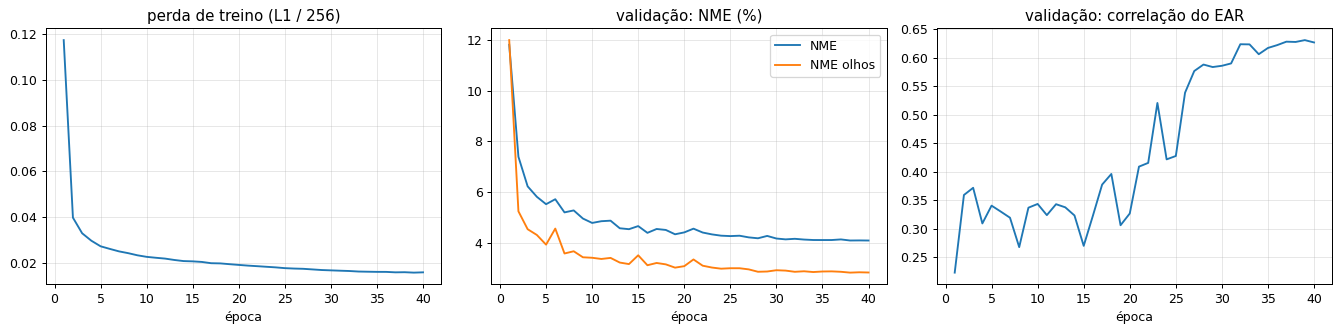

melhor época: 40
  val nme         4.09 %
  val fr10        1.97 %
  val eye_nme     2.83 %
  val ear_corr   0.627
  val ear_mae    0.045


In [8]:
ep = [r["epoch"] for r in log]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(ep, [r["train_loss"] for r in log]); axes[0].set_title("perda de treino (L1 / 256)")
axes[1].plot(ep, [100 * r["val_nme"] for r in log], label="NME")
axes[1].plot(ep, [100 * r["val_eye_nme"] for r in log], label="NME olhos")
axes[1].set_title("validação: NME (%)"); axes[1].legend()
axes[2].plot(ep, [r["val_ear_corr"] for r in log]); axes[2].set_title("validação: correlação do EAR")
for ax in axes:
    ax.set_xlabel("época"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT / "curves.png", dpi=120); plt.show()

ckpt = torch.load(OUT / "best.pt", map_location="cpu", weights_only=False)
print(f"melhor época: {ckpt['epoch']}")
for k, v in ckpt["val"].items():
    print(f"  val {k:9s} {100 * v:6.2f} %" if k in ("nme", "fr10", "eye_nme") else f"  val {k:9s} {v:6.3f}")

### Treino contra validação, sem augmentation

A perda de treino é medida **com** augmentation, então não dá para comparar direto com a
validação. Para uma comparação justa, medimos o NME de 1.000 faces de treino **sem**
augmentation usando o melhor modelo.

In [9]:
model.load_state_dict(ckpt["model"])
train_eval = FaceLandmarks("train", train_idx[:1000], None, dc["input_size"], dc["margin"])
tr = summary(*predict(model, DataLoader(train_eval, 64)))
va = ckpt["val"]
print(f"           NME      olhos    corr EAR")
print(f"treino   {100 * tr['nme']:6.2f} %  {100 * tr['eye_nme']:6.2f} %   {tr['ear_corr']:.3f}")
print(f"validação{100 * va['nme']:6.2f} %  {100 * va['eye_nme']:6.2f} %   {va['ear_corr']:.3f}")

           NME      olhos    corr EAR
treino     3.35 %    2.58 %   0.707
validação  4.09 %    2.83 %   0.627


Se o NME de treino fosse muito menor do que o de validação, seria sinal de overfitting. Se os
dois fossem altos, seria underfitting. A avaliação completa no teste fica para o
`05_avaliacao.ipynb`.